## NicheJepa Model training

Creator: Mohammad Vali Sanian (mohammad.sanian@helsinki.fi) (mv10@sanger.ac.uk).

Date of Creation: 31.08.2024

Date of Last Modification: 1.09.2024

# 1. Setup

## 1.1 Libraries 

In [1]:
import torch
import os
import logging
import anndata as ad
import scanpy as sc
from sklearn.metrics.pairwise import cosine_similarity
from src.nichejepa.train import train
from src.nichejepa.eval import evaluation
from src.nichejepa.utils.config_utils import create_params_from_YAML_wandb_config, prepare_dataset
from src.nichejepa.utils.distributed import init_distributed
from src.nichejepa.utils.eval_utils import clustering_metrics, classification_metrics
import numpy as np


## 1.2 Create params
All setup will be done in the config file. Please edit that file to continue.

In [2]:
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)
params = create_params_from_YAML_wandb_config('configs/simulated_100k.yaml',logger)

INFO:root:Loaded parameters from YAML file.


## 1.3 Create Train,Test dataset

In [3]:
train_dataset, test_dataset = prepare_dataset(params)
train_dataset

Dataset({
    features: ['gene_tokens_cell', 'gene_tokens_neighborhood', 'cell_types', 'niche_types', 'n_nonzero_cell_tokens', 'n_nonzero_neighborhood_tokens', 'n_nonzero_tokens', 'input_ids'],
    num_rows: 80000
})

## 1.4 INIT distributed (it should change later)

In [4]:
devices=['cuda:0']
world_size=1
os.environ['CUDA_VISIBLE_DEVICES'] = str(devices[rank].split(':')[-1])

logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

world_size, rank = init_distributed(rank_and_world_size=(rank, world_size), port=40320)
logger.info(f'Running... (rank: {rank}/{world_size})')

INFO:root:Running... (rank: 0/1)


# 2.Model Training With just_cell and just_neighborhood as True

## 2.1 Train Model

In [ ]:
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40
train(params, train_dataset, test_dataset)

# 3. Analysis With just_cell and just_neighborhood as True

## 3.1 Cell Type Average

In [5]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False
params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384
params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

2963it [01:33, 31.55it/s]
741it [00:23, 31.27it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_average.h5ad


### 3.1.1 Feature Analysis

In [8]:
import anndata as ad

# Now you can access the data in `adata`
print(adata)

print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
#adata.obsm['jepa_emb']




AnnData object with n_obs × n_vars = 100000 × 0
    obs: 'split', 'label_name', 'retrieve_label', 'retrieve_position_emb', 'retrieve_emb_from_layer', 'cell_type', 'gene_count'
    obsm: 'jepa_emb'
[[1.0000001  0.9975889  0.99754524 ... 0.99764097 0.9973074  0.9975701 ]
 [0.9975889  0.99999964 0.9977945  ... 0.9980077  0.99772763 0.9977789 ]
 [0.99754524 0.9977945  1.0000001  ... 0.9981531  0.99772227 0.9976882 ]
 ...
 [0.99764097 0.9980077  0.9981531  ... 1.         0.99808437 0.99797225]
 [0.9973074  0.99772763 0.99772227 ... 0.99808437 1.         0.99787176]
 [0.9975701  0.9977789  0.9976882  ... 0.99797225 0.99787176 1.        ]]


array([[-0.12668091, -0.21605407,  0.02601639, ..., -0.62115   ,
         0.5639685 ,  0.00985935],
       [-0.14169727, -0.28662452,  0.03618073, ..., -0.700044  ,
         0.53300655, -0.07632783],
       [-0.17556438, -0.21058384,  0.03756733, ..., -0.7503702 ,
         0.5162369 ,  0.02056403],
       ...,
       [-0.13755865, -0.2763836 ,  0.06036933, ..., -0.7311635 ,
         0.56134814, -0.06194683],
       [-0.12233038, -0.27928352,  0.03237   , ..., -0.75485885,
         0.54993534,  0.01225239],
       [-0.16436552, -0.25837326,  0.02408466, ..., -0.7279333 ,
         0.5603432 , -0.06256639]], dtype=float32)

### 3.1.2 Umap

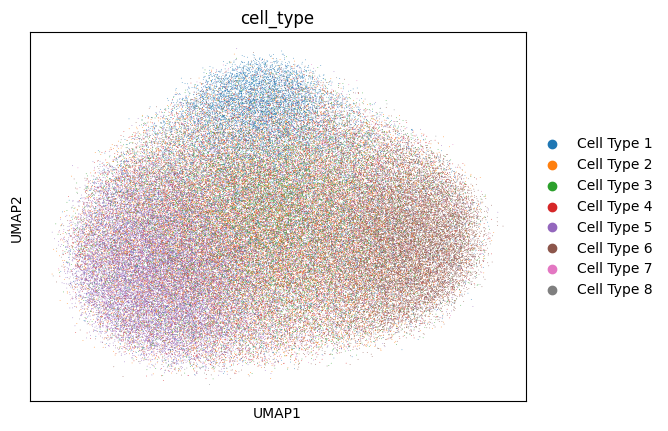

In [9]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.1.3 Logistic regression

In [10]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.76
Test F1 Score: 0.76
Train Accuracy: 0.77
Train F1 Score: 0.77


{'test_accuracy': 0.75905,
 'test_f1': 0.7571606485148727,
 'train_accuracy': 0.7694375,
 'train_f1': 0.7674591305398573}

### 3.1.4 KNeighborsClassifier

In [11]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.46
Test F1 Score: 0.38
Train Accuracy: 0.58
Train F1 Score: 0.53


{'test_accuracy': 0.45975,
 'test_f1': 0.3844486532427803,
 'train_accuracy': 0.58115,
 'train_f1': 0.5333421160548213}

### 3.1.5 nmi&ari

In [12]:
clustering_metrics(adata,label_col='cell_type')

INFO:jax._src.xla_bridge:Unable to initialize backend 'cuda': 
INFO:jax._src.xla_bridge:Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
NMI (Normalized Mutual Information): 0.325457801775342
ARI (Adjusted Rand Index): 0.31898146850571363


{'nmi': 0.325457801775342, 'ari': 0.31898146850571363}

## 3.2 Cell Type CLS

In [13]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 32.32it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.38it/s]
741it [00:24, 30.57it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_cls.h5ad


### 3.2.1 Feature Analysis

In [14]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.         0.99999475 0.99999404 ... 0.99999404 0.9999933  0.9999941 ]
 [0.99999475 1.         0.99999434 ... 0.9999937  0.9999925  0.99999297]
 [0.99999404 0.99999434 1.         ... 0.9999912  0.9999895  0.9999903 ]
 ...
 [0.99999404 0.9999937  0.9999912  ... 1.0000004  0.99999607 0.9999955 ]
 [0.9999933  0.9999925  0.9999895  ... 0.99999607 0.99999976 0.9999958 ]
 [0.9999941  0.99999297 0.9999903  ... 0.9999955  0.9999958  1.0000002 ]]


array([[-0.16273819, -0.38388667,  0.4940811 , ..., -0.17226177,
         0.56310344, -0.36435503],
       [-0.16040611, -0.38282454,  0.49624944, ..., -0.17316467,
         0.56140274, -0.36558867],
       [-0.16037072, -0.380774  ,  0.4961977 , ..., -0.17501934,
         0.5638241 , -0.36385995],
       ...,
       [-0.16332816, -0.3813243 ,  0.4970115 , ..., -0.16554496,
         0.5636225 , -0.36536533],
       [-0.1626432 , -0.3858175 ,  0.49798232, ..., -0.16966103,
         0.56003857, -0.36874908],
       [-0.15957522, -0.38104868,  0.50114995, ..., -0.17162931,
         0.5608688 , -0.36446825]], dtype=float32)

### 3.2.2 Umap

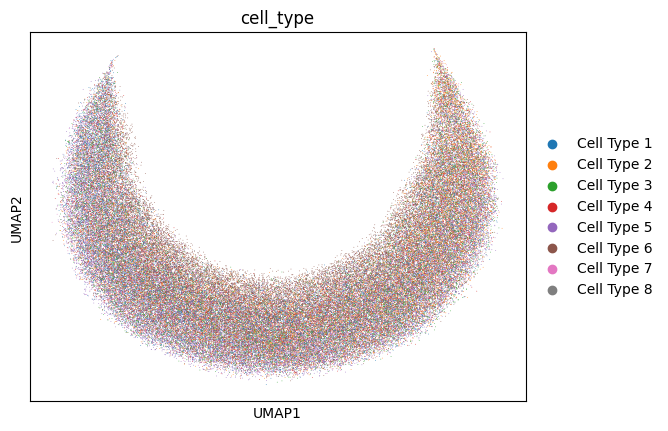

In [15]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.2.3 Logistic regression

In [16]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

Test Accuracy: 0.41
Test F1 Score: 0.30
Train Accuracy: 0.41
Train F1 Score: 0.30


{'test_accuracy': 0.4057,
 'test_f1': 0.3002478238625986,
 'train_accuracy': 0.4068,
 'train_f1': 0.3006151621019086}

### 3.2.4 KNeighborsClassifier

In [17]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.37
Test F1 Score: 0.35
Train Accuracy: 0.59
Train F1 Score: 0.57


{'test_accuracy': 0.3674,
 'test_f1': 0.3516062243870391,
 'train_accuracy': 0.5855875,
 'train_f1': 0.5726809858479593}

### 3.2.5 nmi&ari

In [18]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.004404041193982145
ARI (Adjusted Rand Index): 0.0019272366788603218


{'nmi': 0.004404041193982145, 'ari': 0.0019272366788603218}

## 3.3 Cell Type weighted_average

In [19]:
params['emb']['retrieve_cell'] = True
params['emb']['retrieve_niche'] = False
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2962it [01:34, 32.28it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.36it/s]
741it [00:23, 31.22it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'cell_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_weighted_average.h5ad


### 3.3.1 Feature Analysis

In [20]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.99999976 0.99947834 0.9994741  ... 0.9994558  0.99945855 0.9994743 ]
 [0.99947834 1.         0.9995322  ... 0.99951386 0.99951744 0.99949074]
 [0.9994741  0.9995322  0.99999976 ... 0.9995436  0.9995123  0.9995413 ]
 ...
 [0.9994558  0.99951386 0.9995436  ... 1.0000001  0.9995746  0.9995519 ]
 [0.99945855 0.99951744 0.9995123  ... 0.9995746  0.9999999  0.99956083]
 [0.9994743  0.99949074 0.9995413  ... 0.9995519  0.99956083 1.0000001 ]]


array([[-0.13799755, -0.23203307,  0.02873706, ..., -0.69548875,
         0.55543625, -0.02375149],
       [-0.14139529, -0.258097  ,  0.03798671, ..., -0.71470684,
         0.5486184 , -0.05084332],
       [-0.16128813, -0.22705153,  0.04229118, ..., -0.7236278 ,
         0.53894943, -0.02485326],
       ...,
       [-0.13726479, -0.2485533 ,  0.05126147, ..., -0.7330958 ,
         0.5555131 , -0.0590924 ],
       [-0.1328356 , -0.25883484,  0.03542446, ..., -0.74666214,
         0.560251  , -0.01265608],
       [-0.16107816, -0.25511837,  0.04301759, ..., -0.7226412 ,
         0.5543915 , -0.04807315]], dtype=float32)

### 3.3.2 Umap

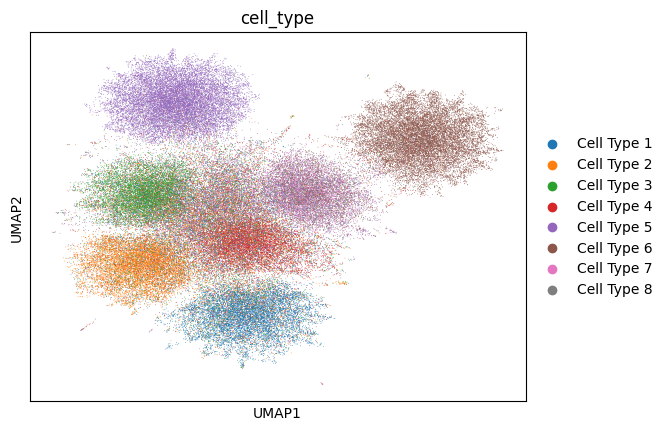

In [21]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='cell_type')

### 3.3.3 Logistic regression

In [22]:
classification_metrics(adata, label_col='cell_type', classifier='logistic')

/nfs/team361/mv10/.jepa/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test Accuracy: 0.77
Test F1 Score: 0.76
Train Accuracy: 0.77
Train F1 Score: 0.77


{'test_accuracy': 0.765,
 'test_f1': 0.7642862383689242,
 'train_accuracy': 0.768925,
 'train_f1': 0.7680796048711023}

### 3.3.4 KNN

In [23]:
classification_metrics(adata, label_col='cell_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.63
Test F1 Score: 0.63
Train Accuracy: 0.73
Train F1 Score: 0.73


{'test_accuracy': 0.6323,
 'test_f1': 0.6321137514052035,
 'train_accuracy': 0.731075,
 'train_f1': 0.7317564975110998}

### 3.3.5 nmi&ari

In [24]:
clustering_metrics(adata,label_col='cell_type')

NMI (Normalized Mutual Information): 0.4592381832398499
ARI (Adjusted Rand Index): 0.40913826946163473


{'nmi': 0.4592381832398499, 'ari': 0.40913826946163473}

## 3.4 Niche Type Average

In [25]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=True
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True

params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2962it [01:34, 32.18it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.46it/s]
741it [00:23, 31.31it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_average.h5ad


### 3.4.1 Feature Analysis

In [26]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.9999998  0.99999243 0.99999213 ... 0.99999213 0.9999925  0.999993  ]
 [0.99999243 0.9999999  0.9999921  ... 0.9999939  0.9999933  0.9999933 ]
 [0.99999213 0.9999921  1.         ... 0.99999344 0.9999923  0.9999919 ]
 ...
 [0.99999213 0.9999939  0.99999344 ... 1.         0.99999464 0.99999416]
 [0.9999925  0.9999933  0.9999923  ... 0.99999464 1.0000001  0.9999943 ]
 [0.999993   0.9999933  0.9999919  ... 0.99999416 0.9999943  0.99999994]]


array([[-0.14217958, -0.24776313,  0.03762787, ..., -0.73470354,
         0.5543465 , -0.03255085],
       [-0.13956611, -0.24551527,  0.03925084, ..., -0.7347009 ,
         0.55406475, -0.032904  ],
       [-0.14030725, -0.24242838,  0.0396403 , ..., -0.7358252 ,
         0.55503225, -0.03050037],
       ...,
       [-0.14214155, -0.24567981,  0.04143601, ..., -0.7291384 ,
         0.5558027 , -0.03136822],
       [-0.1414745 , -0.24851765,  0.04183475, ..., -0.731724  ,
         0.55291605, -0.03416537],
       [-0.13880123, -0.2443546 ,  0.04346211, ..., -0.73547465,
         0.552687  , -0.0296597 ]], dtype=float32)

### 3.4.2 Umap

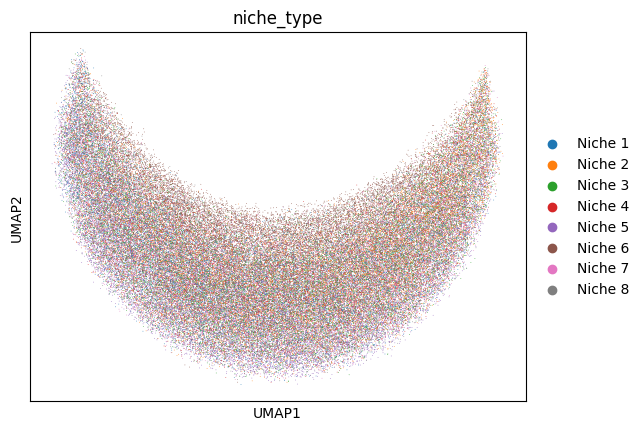

In [27]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.4.3 Logistic regression

In [28]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.44
Test F1 Score: 0.36
Train Accuracy: 0.44
Train F1 Score: 0.36


{'test_accuracy': 0.44095,
 'test_f1': 0.3556604585406429,
 'train_accuracy': 0.4437875,
 'train_f1': 0.3582307640233953}

### 3.4.4 KNN

In [29]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.36
Test F1 Score: 0.34
Train Accuracy: 0.58
Train F1 Score: 0.57


{'test_accuracy': 0.36015,
 'test_f1': 0.3411529976450644,
 'train_accuracy': 0.5836375,
 'train_f1': 0.5697392098345188}

### 3.4.5 nmi&ari

In [30]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.015247785150877446
ARI (Adjusted Rand Index): 0.00880506558403067


{'nmi': 0.015247785150877446, 'ari': 0.00880506558403067}

## 3.5 Niche Type CLS

In [31]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=False
params['emb']['average']=False
params['emb']['cls']=True

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True


params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40


adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2961it [01:33, 32.13it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.48it/s]
741it [00:23, 30.98it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_cls.h5ad


### 3.5.1 Feature Analysis

In [32]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[1.         0.99999475 0.99999404 ... 0.99999404 0.9999933  0.9999941 ]
 [0.99999475 1.         0.99999434 ... 0.9999937  0.9999925  0.99999297]
 [0.99999404 0.99999434 1.         ... 0.9999912  0.9999895  0.9999903 ]
 ...
 [0.99999404 0.9999937  0.9999912  ... 1.0000004  0.99999607 0.9999955 ]
 [0.9999933  0.9999925  0.9999895  ... 0.99999607 0.99999976 0.9999958 ]
 [0.9999941  0.99999297 0.9999903  ... 0.9999955  0.9999958  1.0000002 ]]


array([[-0.16273819, -0.38388667,  0.4940811 , ..., -0.17226177,
         0.56310344, -0.36435503],
       [-0.16040611, -0.38282454,  0.49624944, ..., -0.17316467,
         0.56140274, -0.36558867],
       [-0.16037072, -0.380774  ,  0.4961977 , ..., -0.17501934,
         0.5638241 , -0.36385995],
       ...,
       [-0.16332816, -0.3813243 ,  0.4970115 , ..., -0.16554496,
         0.5636225 , -0.36536533],
       [-0.1626432 , -0.3858175 ,  0.49798232, ..., -0.16966103,
         0.56003857, -0.36874908],
       [-0.15957522, -0.38104868,  0.50114995, ..., -0.17162931,
         0.5608688 , -0.36446825]], dtype=float32)

### 3.5.2 Umap

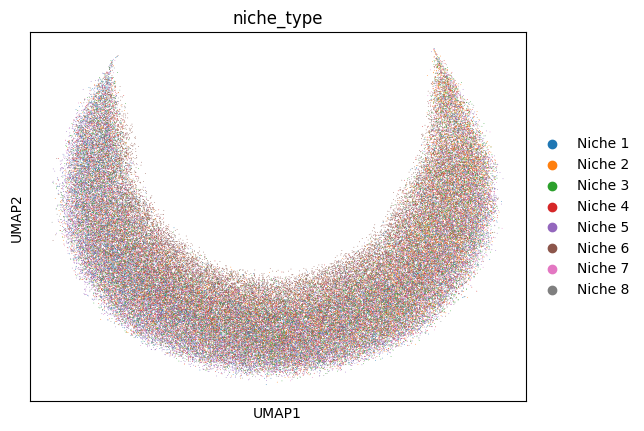

In [33]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.5.3 Logistic regression

In [34]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.44
Test F1 Score: 0.36
Train Accuracy: 0.44
Train F1 Score: 0.36


{'test_accuracy': 0.4406,
 'test_f1': 0.36236897050926475,
 'train_accuracy': 0.442025,
 'train_f1': 0.3641801275183315}

### 3.5.4 KNN

In [35]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.33
Test F1 Score: 0.31
Train Accuracy: 0.56
Train F1 Score: 0.55


{'test_accuracy': 0.3256,
 'test_f1': 0.3088677026564968,
 'train_accuracy': 0.5612625,
 'train_f1': 0.5498399439591076}

### 3.5.5 nmi&ari

In [36]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.0035520940553680266
ARI (Adjusted Rand Index): 0.001433178079436171


{'nmi': 0.0035520940553680266, 'ari': 0.001433178079436171}

## 3.6 Niche Type weighted_average

In [37]:
params['emb']['retrieve_cell'] = False
params['emb']['retrieve_niche'] = True
params['emb']['retrieve_gene'] = False
params['emb']['weighted_average']=True
params['emb']['average']=False
params['emb']['cls']=False

params['data']['just_cell'] = True
params['data']['just_neighborhood'] = True


params['mask']['n_contexts'] = 1
params['mask']['n_targets'] = 9
params['mask']['per_segment_mask_ratio'] = 0.2


params['meta']['pred_emb_dim'] = 192
params['meta']['enc_emb_dim'] = 384

params['meta']['pred_depth'] = 1
params['meta']['enc_depth'] = 3

params['optimization']['pos_learnable'] = 1
params['optimization']['seg_learnable'] = 0
params['optimization']['epochs'] = 40

adata = evaluation(params, train_dataset, test_dataset)

INFO:root:GeneTransformerEncoder(
  (gene_embed): Embedding(1108, 384, padding_idx=0)
  (seg_embed): Embedding(3, 384, padding_idx=0)
  (blocks): ModuleList(
    (0-2): 3 x Block(
      (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=384, out_features=1152, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=384, out_features=1536, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=1536, out_features=384, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
)
INFO:root:Data loader created.
INFO:root:Data loader 

/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2960it [01:34, 32.23it/s]/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
2963it [01:34, 31.29it/s]
741it [00:23, 31.01it/s]
... storing 'split' as categorical
... storing 'label_name' as categorical
... storing 'retrieve_label' as categorical
... storing 'niche_type' as categorical


AnnData has been successfully saved at: logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_weighted_average.h5ad


### 3.6.1 Feature Analysis

In [38]:
print(cosine_similarity(adata.obsm['jepa_emb'][:100, :]))
adata.obsm['jepa_emb']
adata.obsm['jepa_emb']

[[0.99999976 0.99947834 0.9994741  ... 0.9994558  0.99945855 0.9994743 ]
 [0.99947834 1.         0.9995322  ... 0.99951386 0.99951744 0.99949074]
 [0.9994741  0.9995322  0.99999976 ... 0.9995436  0.9995123  0.9995413 ]
 ...
 [0.9994558  0.99951386 0.9995436  ... 1.0000001  0.9995746  0.9995519 ]
 [0.99945855 0.99951744 0.9995123  ... 0.9995746  0.9999999  0.99956083]
 [0.9994743  0.99949074 0.9995413  ... 0.9995519  0.99956083 1.0000001 ]]


array([[-0.13799755, -0.23203307,  0.02873706, ..., -0.69548875,
         0.55543625, -0.02375149],
       [-0.14139529, -0.258097  ,  0.03798671, ..., -0.71470684,
         0.5486184 , -0.05084332],
       [-0.16128813, -0.22705153,  0.04229118, ..., -0.7236278 ,
         0.53894943, -0.02485326],
       ...,
       [-0.13726479, -0.2485533 ,  0.05126147, ..., -0.7330958 ,
         0.5555131 , -0.0590924 ],
       [-0.1328356 , -0.25883484,  0.03542446, ..., -0.74666214,
         0.560251  , -0.01265608],
       [-0.16107816, -0.25511837,  0.04301759, ..., -0.7226412 ,
         0.5543915 , -0.04807315]], dtype=float32)

### 3.6.2 Umap

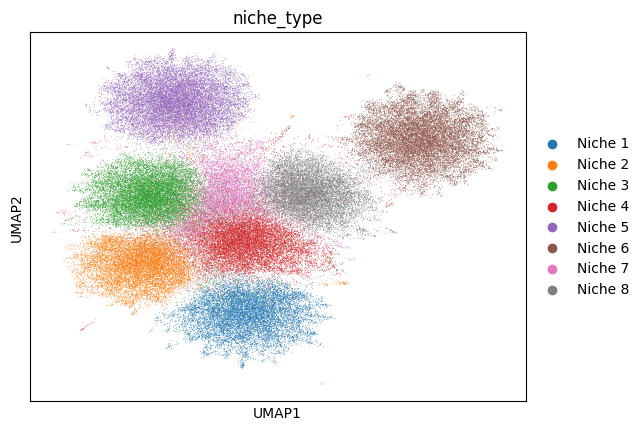

In [39]:
sc.pp.neighbors(adata, n_neighbors=5, use_rep='jepa_emb')
sc.tl.umap(adata)

# Plot the UMAP
sc.pl.umap(adata, color='niche_type')

### 3.6.3 Logistic regression

In [40]:
classification_metrics(adata, label_col='niche_type', classifier='logistic')

Test Accuracy: 0.98
Test F1 Score: 0.98
Train Accuracy: 0.98
Train F1 Score: 0.98


{'test_accuracy': 0.97545,
 'test_f1': 0.9753875618201866,
 'train_accuracy': 0.976725,
 'train_f1': 0.9766722158920622}

### 3.6.4 KNN

In [41]:
classification_metrics(adata, label_col='niche_type', classifier='knn', n_neighbors=5)

Test Accuracy: 0.99
Test F1 Score: 0.99
Train Accuracy: 0.99
Train F1 Score: 0.99


{'test_accuracy': 0.98905,
 'test_f1': 0.9890420177579077,
 'train_accuracy': 0.9936375,
 'train_f1': 0.9936357660012815}

### 3.6.5 nmi&ari

In [42]:
clustering_metrics(adata,label_col='niche_type')

NMI (Normalized Mutual Information): 0.889803722413405
ARI (Adjusted Rand Index): 0.9041823260209946


{'nmi': 0.889803722413405, 'ari': 0.9041823260209946}

## 3.7 Box plot of correlation between embeddings

In [43]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def compute_similarity_stats(adata, embedding_key='jepa_emb', type_key='niche_type', n_samples=10000, random_state=42):
    """
    Function to compute mean and variance of cosine similarity between pairs of types (e.g., cell types).
    
    Parameters:
    - adata: AnnData object containing the data.
    - embedding_key: The key to use in .obsm for the embeddings (default: 'jepa_emb').
    - type_key: The key in .obs used to stratify and differentiate types (default: 'niche_type').
    - n_samples: Number of samples to draw from the dataset (default: 10000).
    - random_state: Seed for reproducibility (default: 42).
    
    Returns:
    - A DataFrame with mean and variance of cosine similarities between each pair of types.
    """
    
    # Stratified sampling based on the specified types
    types = adata.obs[type_key]
    if n_samples is not None:
      sampled_indices, _ = train_test_split(
        np.arange(adata.n_obs), 
        train_size=n_samples, 
        stratify=types, 
        random_state=random_state
      )
    
      # Subset the AnnData object to keep only the sampled cells
      adata_sampled = adata[sampled_indices].copy()
    else:
      adata_sampled = adata  
    # Extract the embeddings or the data matrix (from .obsm)
    data = adata_sampled.obsm[embedding_key]  # Replace with appropriate layer if necessary

    # Get the unique types
    unique_types = adata_sampled.obs[type_key].unique()

    # List to store the results for each class pair
    similarity_stats_list = []

    # Compute similarity between each pair of types
    for i, type_1 in enumerate(unique_types):
        for j, type_2 in enumerate(unique_types):
            # Select cells of the respective types
            cells_1 = data[adata_sampled.obs[type_key] == type_1]
            cells_2 = data[adata_sampled.obs[type_key] == type_2]

            # Compute pairwise cosine similarity between cells from type 1 and type 2
            similarity_matrix = cosine_similarity(cells_1, cells_2)
            # Compute mean and variance of the similarity scores
            mean_similarity = np.mean(similarity_matrix)
            variance_similarity = np.var(similarity_matrix)

            # Append results to the list
            similarity_stats_list.append({
                'Class 1': type_1,
                'Class 2': type_2,
                'Mean Similarity': mean_similarity,
                'Variance Similarity': variance_similarity
            })

    # Convert the list to a DataFrame
    similarity_stats = pd.DataFrame(similarity_stats_list)

    # Optionally print the resulting DataFrame
    print(similarity_stats)

    # Return the similarity stats DataFrame
    return similarity_stats

# Example usage:
# similarity_stats = compute_similarity_stats(adata)


In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_similarity_heatmaps(similarity_stats, title_mean='Mean Similarity Between Types', title_variance='Variance of Similarity Between Types'):
    """
    Function to create and display two heatmaps for Mean Similarity and Variance Similarity side by side.
    
    Parameters:
    - similarity_stats: DataFrame containing the similarity statistics with 'Class 1', 'Class 2', 'Mean Similarity', and 'Variance Similarity'.
    - title_mean: Title for the mean similarity heatmap (default: 'Mean Similarity Between Types').
    - title_variance: Title for the variance similarity heatmap (default: 'Variance of Similarity Between Types').
    
    Returns:
    - Displays two heatmaps (Mean Similarity and Variance Similarity).
    """
    # Create pivot tables for mean similarity and variance similarity
    similarity_pivot_mean = similarity_stats.pivot(index='Class 1', columns='Class 2', values='Mean Similarity')
    similarity_pivot_variance = similarity_stats.pivot(index='Class 1', columns='Class 2', values='Variance Similarity')
    
    # Create the figure and two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    
    # Mean similarity heatmap
    sns.heatmap(similarity_pivot_mean, annot=True, cmap="coolwarm", cbar=True, fmt=".2f", ax=axes[0])
    axes[0].set_title(title_mean)
    axes[0].set_xlabel('Class 2')
    axes[0].set_ylabel('Class 1')
    
    # Variance similarity heatmap
    sns.heatmap(similarity_pivot_variance, annot=True, cmap="coolwarm", cbar=True, fmt=".2f", ax=axes[1])
    axes[1].set_title(title_variance)
    axes[1].set_xlabel('Class 2')
    axes[1].set_ylabel('Class 1')
    
    # Adjust the layout
    plt.tight_layout()
    
    # Display the heatmaps
    plt.show()

# Example usage:
# plot_similarity_heatmaps(similarity_stats)


### 3.7.1 Cell Type Average

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7         0.997648         5.600712e-08
1   Cell Type 7  Cell Type 6         0.997705         5.586527e-08
2   Cell Type 7  Cell Type 4         0.997592         5.451450e-08
3   Cell Type 7  Cell Type 2         0.997592         5.506462e-08
4   Cell Type 7  Cell Type 8         0.997559         5.656278e-08
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2         0.997829         7.363439e-08
60  Cell Type 5  Cell Type 8         0.997673         5.726494e-08
61  Cell Type 5  Cell Type 3         0.997930         9.690375e-08
62  Cell Type 5  Cell Type 1         0.997870         8.250095e-08
63  Cell Type 5  Cell Type 5         0.997274         3.732233e-07

[64 rows x 4 columns]


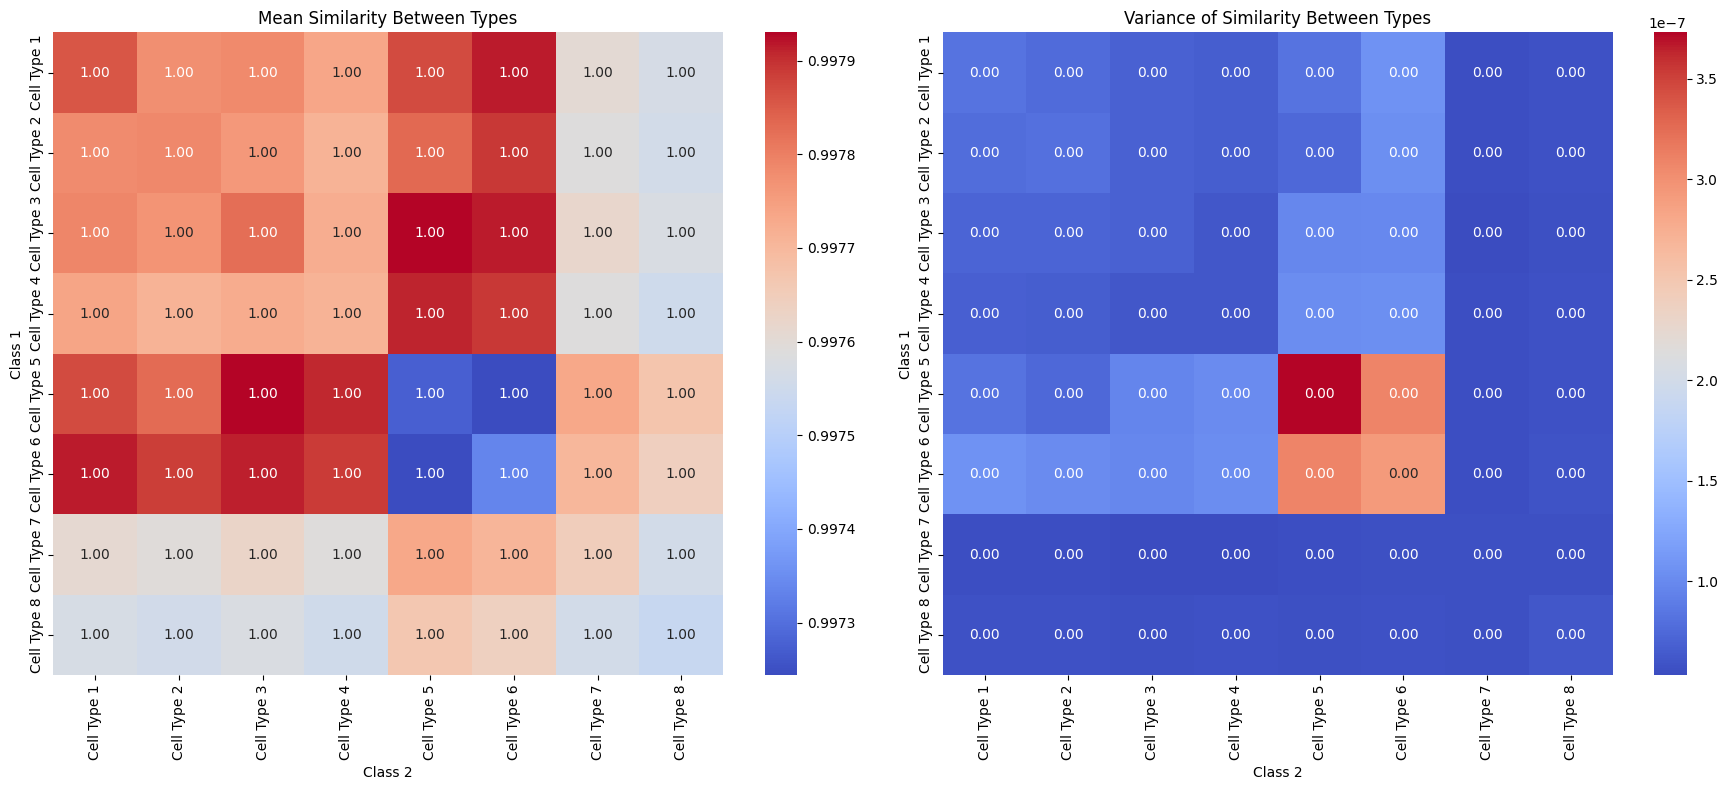

In [45]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.2 Cell Type CLS

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7         0.999999         4.408177e-11
1   Cell Type 7  Cell Type 6         1.000000         5.193879e-11
2   Cell Type 7  Cell Type 4         1.000000         5.108163e-11
3   Cell Type 7  Cell Type 2         1.000000         5.481882e-11
4   Cell Type 7  Cell Type 8         0.999999         4.490527e-11
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2         1.000000         5.572642e-11
60  Cell Type 5  Cell Type 8         1.000000         5.159480e-11
61  Cell Type 5  Cell Type 3         1.000000         5.359133e-11
62  Cell Type 5  Cell Type 1         1.000000         5.424295e-11
63  Cell Type 5  Cell Type 5         1.000000         5.200375e-11

[64 rows x 4 columns]


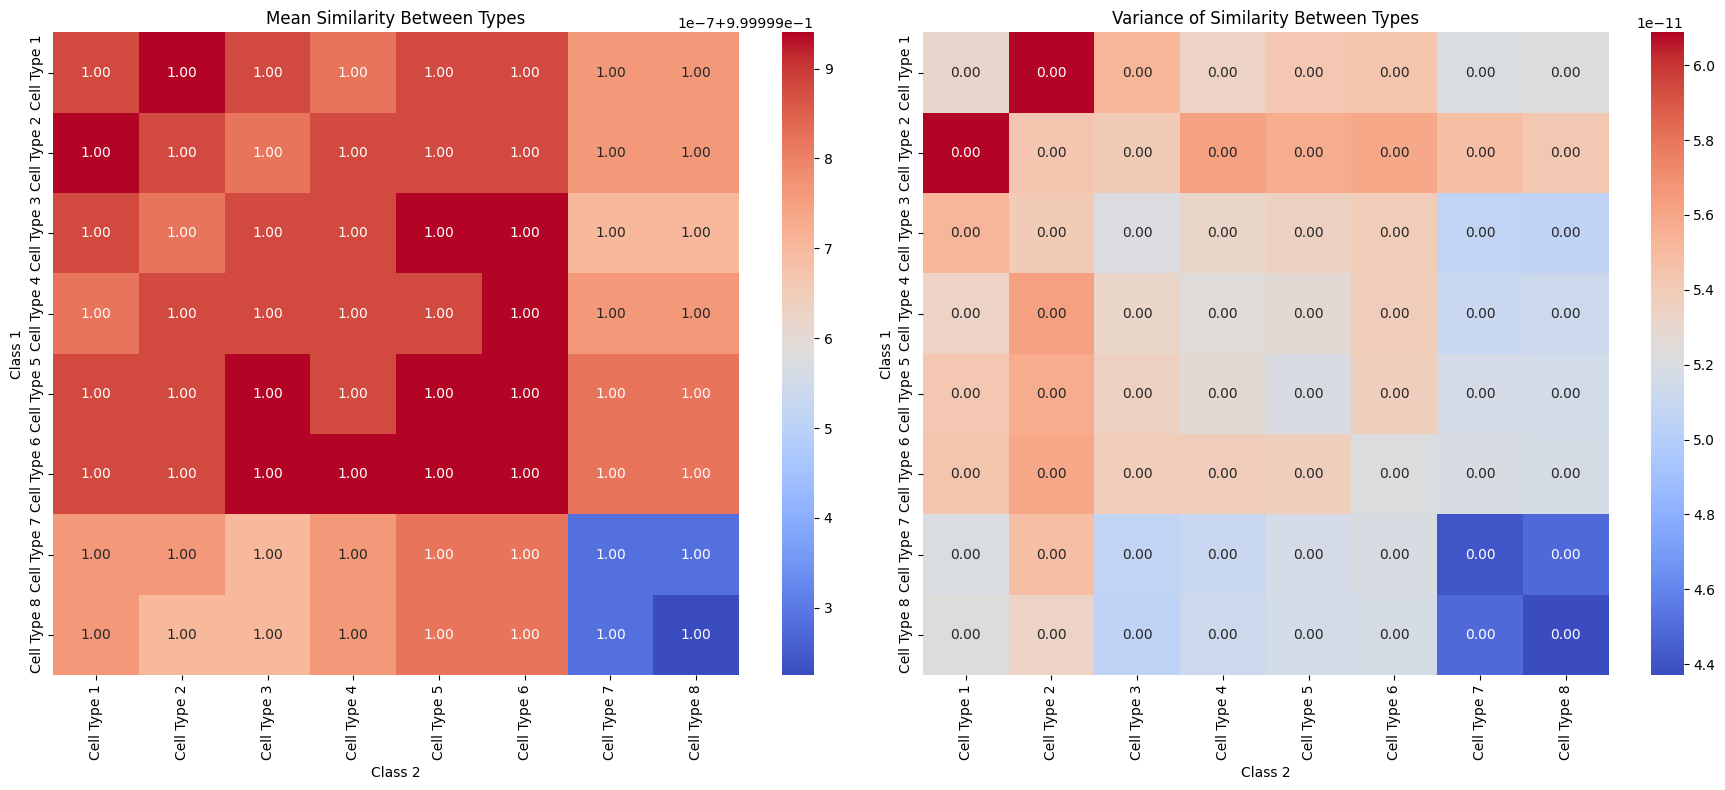

In [46]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_cls.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.3 Cell Type weighted Average

        Class 1      Class 2  Mean Similarity  Variance Similarity
0   Cell Type 7  Cell Type 7         0.999518         2.110881e-09
1   Cell Type 7  Cell Type 6         0.999468         3.123156e-09
2   Cell Type 7  Cell Type 4         0.999511         1.839494e-09
3   Cell Type 7  Cell Type 2         0.999511         1.823114e-09
4   Cell Type 7  Cell Type 8         0.999515         1.880514e-09
..          ...          ...              ...                  ...
59  Cell Type 5  Cell Type 2         0.999723         5.103714e-08
60  Cell Type 5  Cell Type 8         0.999474         2.886142e-09
61  Cell Type 5  Cell Type 3         0.999676         3.368207e-08
62  Cell Type 5  Cell Type 1         0.999675         3.760401e-08
63  Cell Type 5  Cell Type 5         0.999902         1.371764e-07

[64 rows x 4 columns]


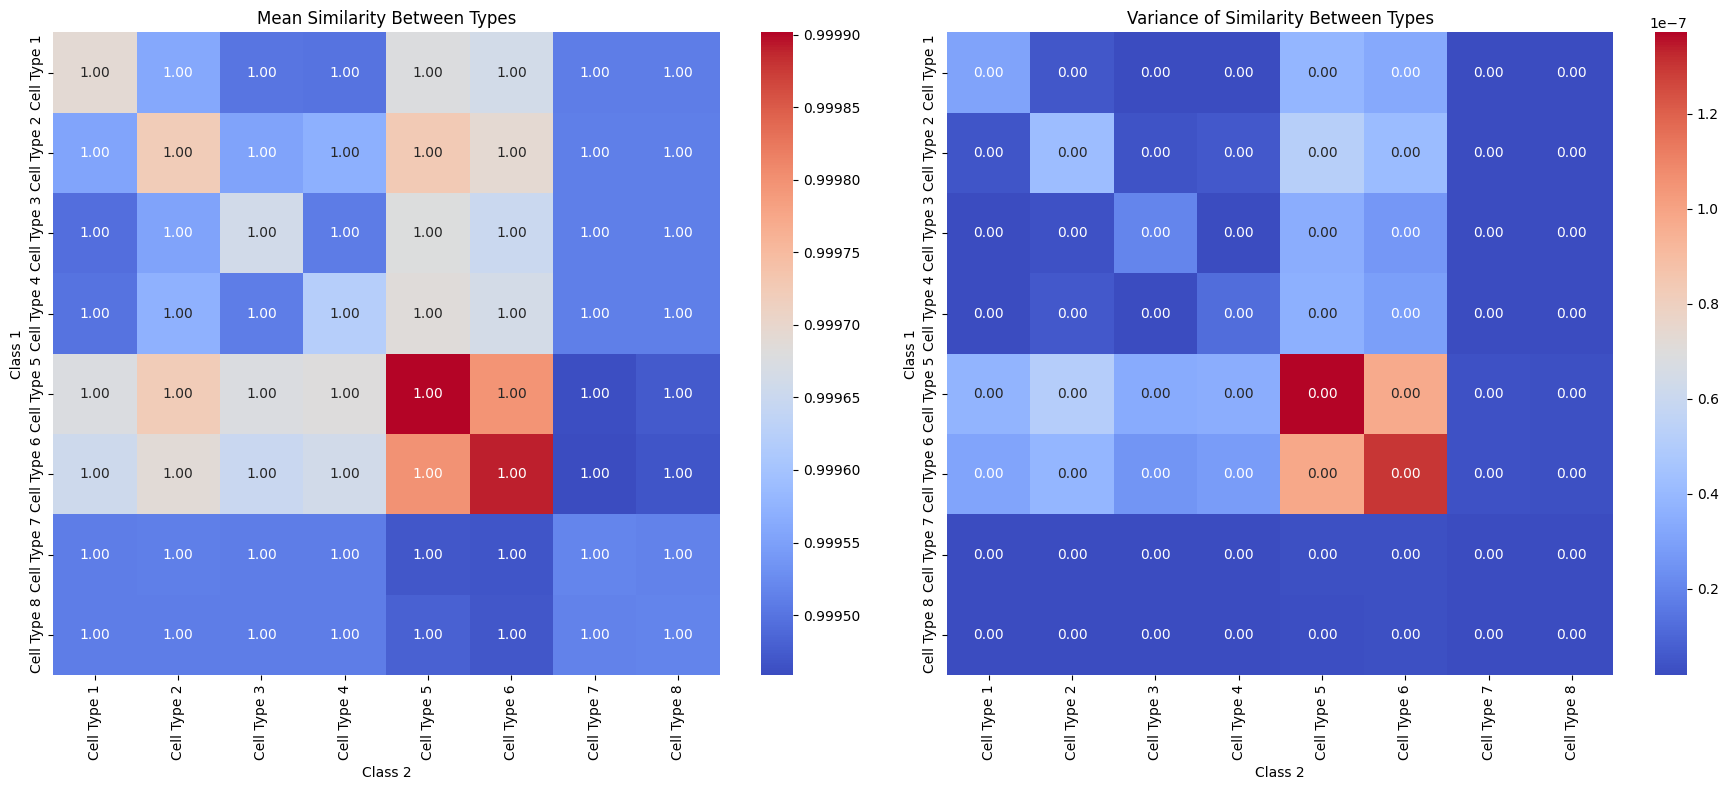

In [47]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/cell_embedding_weighted_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='cell_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.4 Niche Type Average

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7              1.0         4.805399e-11
1   Niche 7  Niche 4              1.0         4.977922e-11
2   Niche 7  Niche 6              1.0         5.006417e-11
3   Niche 7  Niche 3              1.0         4.812334e-11
4   Niche 7  Niche 2              1.0         4.920138e-11
..      ...      ...              ...                  ...
59  Niche 5  Niche 3              1.0         5.017796e-11
60  Niche 5  Niche 2              1.0         5.049850e-11
61  Niche 5  Niche 8              1.0         4.914888e-11
62  Niche 5  Niche 1              1.0         5.106011e-11
63  Niche 5  Niche 5              1.0         4.463365e-11

[64 rows x 4 columns]


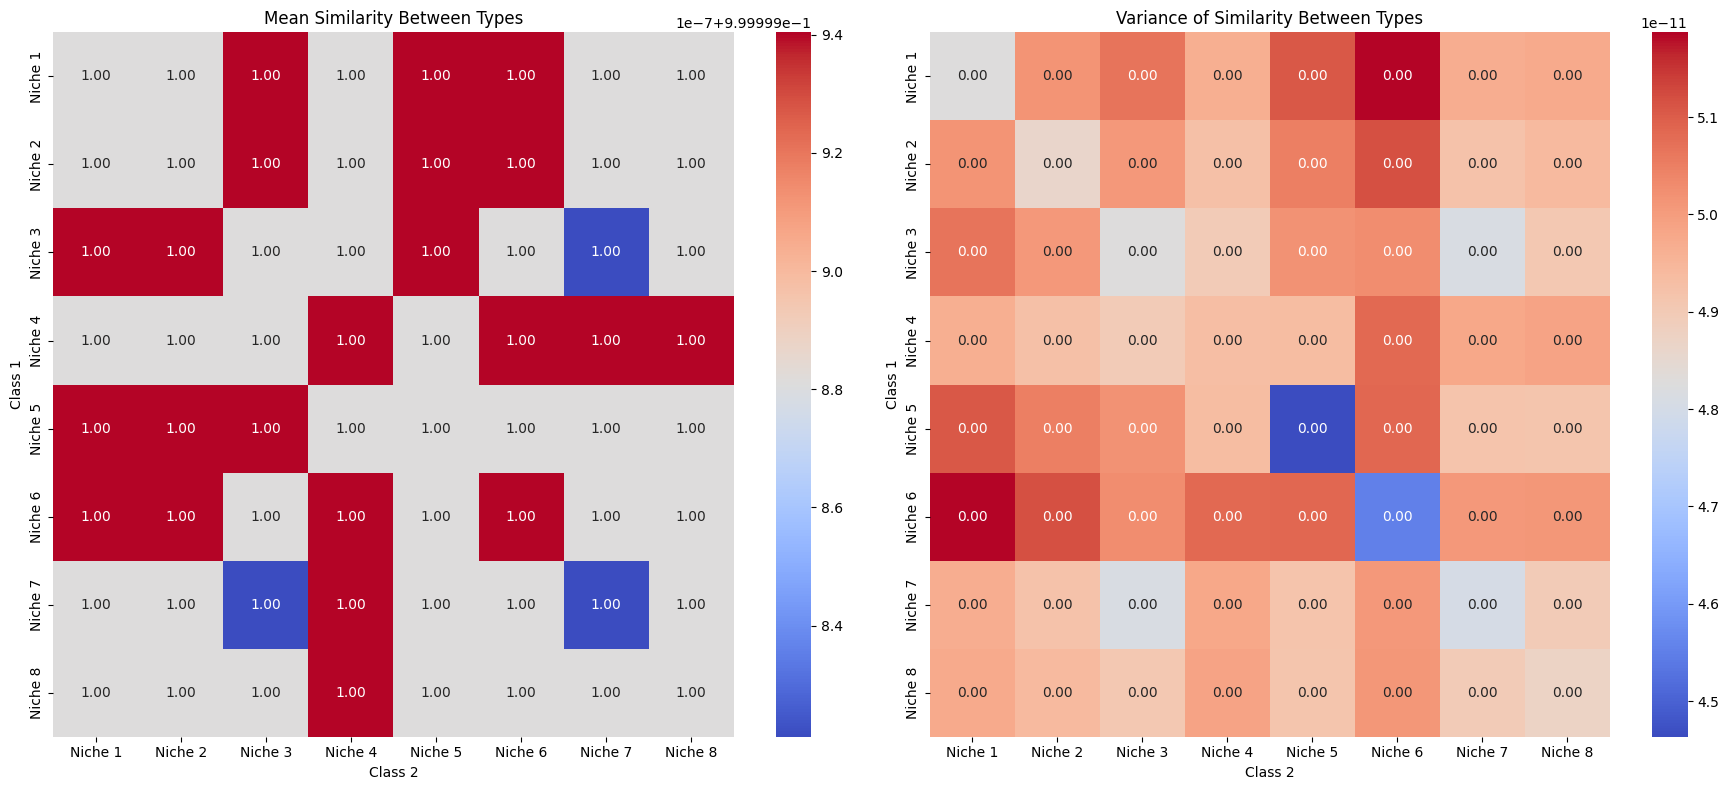

In [48]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.5 Niche Type CLS

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7              1.0         5.212906e-11
1   Niche 7  Niche 4              1.0         5.393554e-11
2   Niche 7  Niche 6              1.0         5.294284e-11
3   Niche 7  Niche 3              1.0         5.226031e-11
4   Niche 7  Niche 2              1.0         5.535855e-11
..      ...      ...              ...                  ...
59  Niche 5  Niche 3              1.0         5.377806e-11
60  Niche 5  Niche 2              1.0         5.684891e-11
61  Niche 5  Niche 8              1.0         5.247962e-11
62  Niche 5  Niche 1              1.0         5.457218e-11
63  Niche 5  Niche 5              1.0         4.938658e-11

[64 rows x 4 columns]


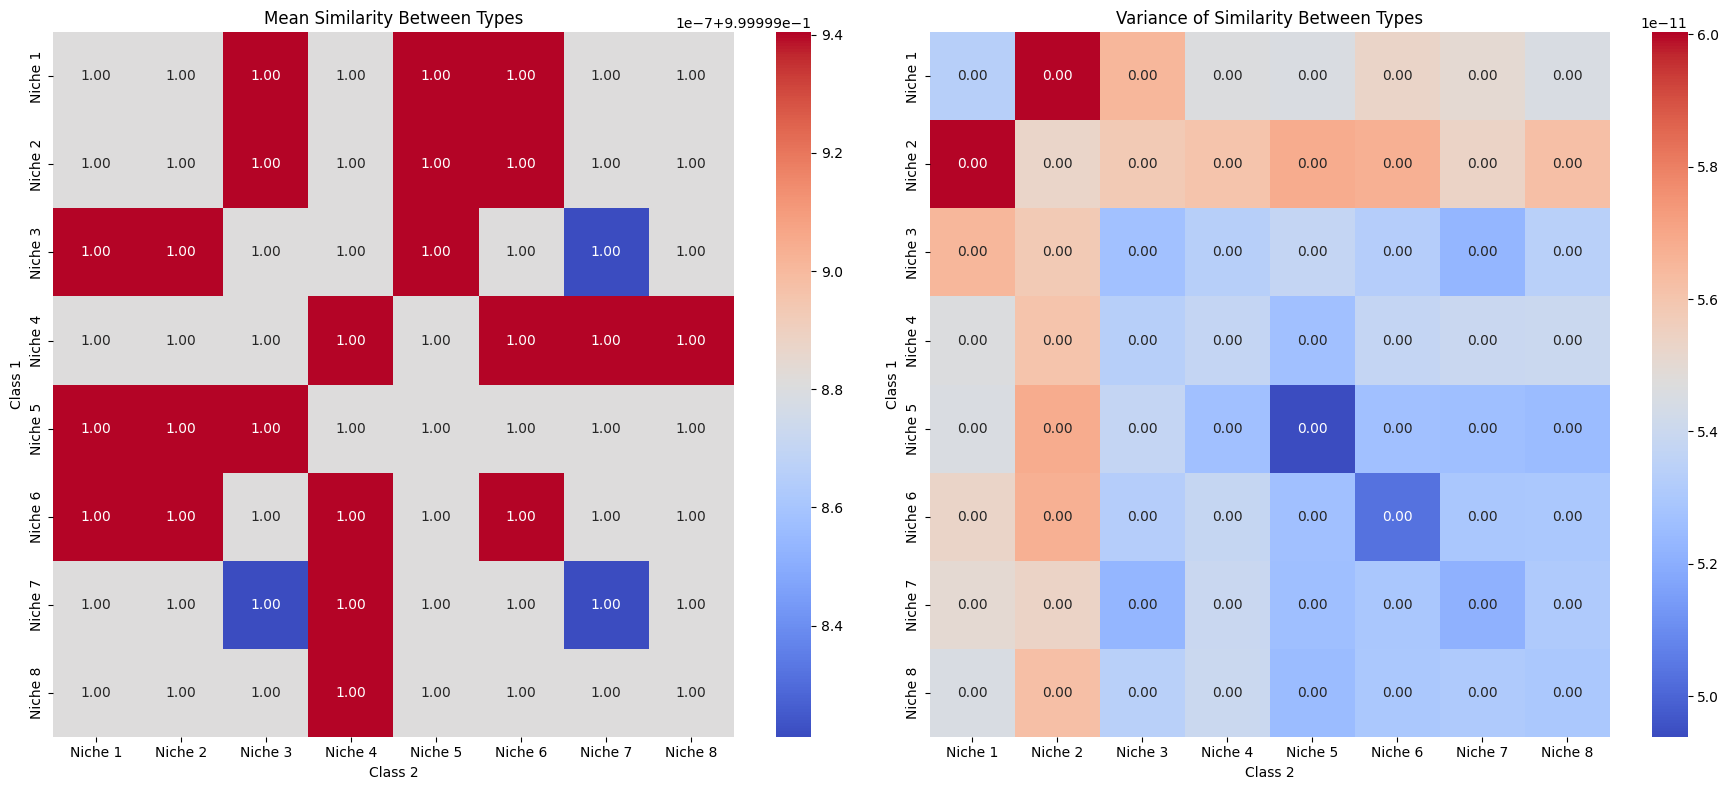

In [49]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_cls.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)

### 3.7.6 Niche Type weighted_average

    Class 1  Class 2  Mean Similarity  Variance Similarity
0   Niche 7  Niche 7         0.999603         8.479109e-09
1   Niche 7  Niche 4         0.999514         1.804684e-09
2   Niche 7  Niche 6         0.999403         9.916049e-09
3   Niche 7  Niche 3         0.999545         2.956467e-09
4   Niche 7  Niche 2         0.999478         2.639936e-09
..      ...      ...              ...                  ...
59  Niche 5  Niche 3         0.999552         5.624010e-09
60  Niche 5  Niche 2         0.999491         1.846614e-09
61  Niche 5  Niche 8         0.999484         1.959021e-09
62  Niche 5  Niche 1         0.999404         7.366000e-09
63  Niche 5  Niche 5         0.999842         7.504430e-08

[64 rows x 4 columns]


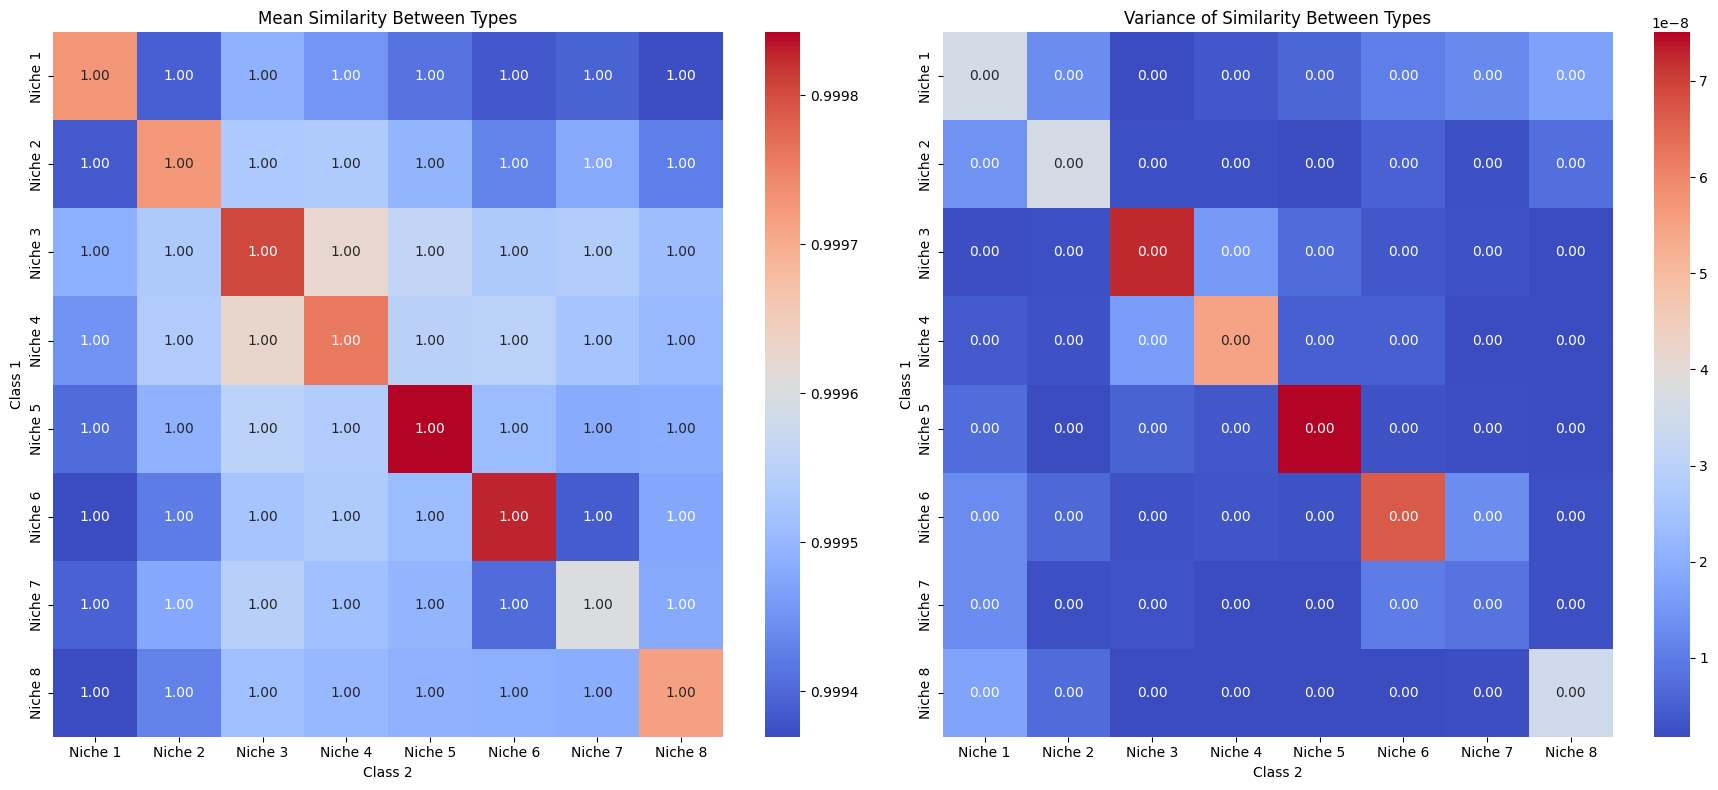

In [50]:
# File path
file_path = f'logs/simulated_100k_pred_depth_1_pred_emb_dim_192_enc_depth_3_enc_emb_dim_384_n_targets_9_n_contexts_1_target_mask_size_10_context_mask_size_1240_num_epochs_40_seq_len_cell_374_pos_learnable_1_seg_learnable_0_seq_len_neighborhood_1105_total/extracted_features/niche_embedding_weighted_average.h5ad'
adata = ad.read_h5ad(file_path)

# Load the .h5ad file
similarity_stats = compute_similarity_stats(adata,n_samples=None,type_key='niche_type')
plot_similarity_heatmaps(similarity_stats)